In [1]:
import numpy as np
import matplotlib as mpl
%matplotlib inline
import matplotlib.pyplot as plt

In [2]:
sensor_field = np.loadtxt('W-9279.csv', dtype=str, skiprows=1, usecols=0, delimiter=',')
sensor_ctime,sensor_val = np.loadtxt('W-9279.csv', unpack=True, usecols=[1,2], skiprows=1, delimiter=',')

In [144]:
print(sensor_ctime.shape, sensor_val.shape)

(269325,) (269325,)


In [3]:
fields = np.unique(sensor_field)
sensor_dict = {}
for field in fields:
    field_inds = np.where(sensor_field == field)[0]
    
    try:
        sensor_dict[field]
    except KeyError:
        sensor_dict[field] = np.vstack((sensor_ctime[field_inds], sensor_val[field_inds])).T

In [4]:
print([(f, sensor_dict[f].shape) for f in fields])

[(np.str_('gps_altitude'), (66982, 2)), (np.str_('humidity_1'), (66982, 2)), (np.str_('humidity_2'), (66982, 2)), (np.str_('pressure'), (1397, 2)), (np.str_('temperature_ambient'), (66982, 2))]


In [10]:
# Quick check that the ctime values of equal-length vectors are identical
print(np.all(sensor_dict['humidity_1'][:,0] == sensor_dict['temperature_ambient'][:,0]))
print(np.all(sensor_dict['gps_altitude'][:,0] == sensor_dict['temperature_ambient'][:,0]))

True
True


In [6]:
# Looking for NaN values in all fields
h1_nans = np.sum(np.isnan(sensor_dict['humidity_1'][:,1]))
h2_nans = np.sum(np.isnan(sensor_dict['humidity_2'][:,1]))
alt_nans = np.sum(np.isnan(sensor_dict['gps_altitude'][:,1]))
temp_nans = np.sum(np.isnan(sensor_dict['temperature_ambient'][:,1]))
pressure_nans = np.sum(np.isnan(sensor_dict['pressure'][:,1]))

In [9]:
print(h1_nans, h2_nans, alt_nans, temp_nans, pressure_nans)

0 0 0 0 0


In [11]:
# Aliases for the ctime and the sensor vectors
ct = sensor_dict['humidity_1'][:,0]
alt_vec = sensor_dict['gps_altitude'][:,1]
h1_vec = sensor_dict['humidity_1'][:,1]
h2_vec = sensor_dict['humidity_2'][:,1]
temp_vec = sensor_dict['temperature_ambient'][:,1]

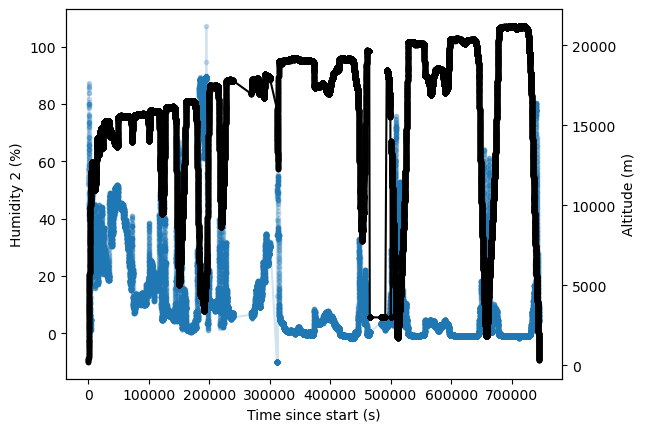

In [13]:
# Sanity check plot of humidity, altitude on common time basis
plt.plot(ct - ct[0], h2_vec, '.-', alpha=0.2)
plt.xlabel('Time since start (s)')
plt.ylabel('Humidity 2 (%)')
    
ax = plt.twinx()
ax.plot(ct - ct[0], alt_vec, 'k.-')
ax.set_ylabel('Altitude (m)')

#plt.xlim(295000, 325000)

plt.show()
plt.close()

In [14]:
# Are repeated values common in the altitude vector? Turns out, they are
np.sum(np.diff(alt_vec) == 0)

np.int64(37720)

In [15]:
# Consider alt vec flags first -- base local values in other arrays off smooth behavior vs altitude
# This is nearest-neighbor estimate of derivative per sample
alt_num_deriv = np.diff(alt_vec)/np.diff(ct)

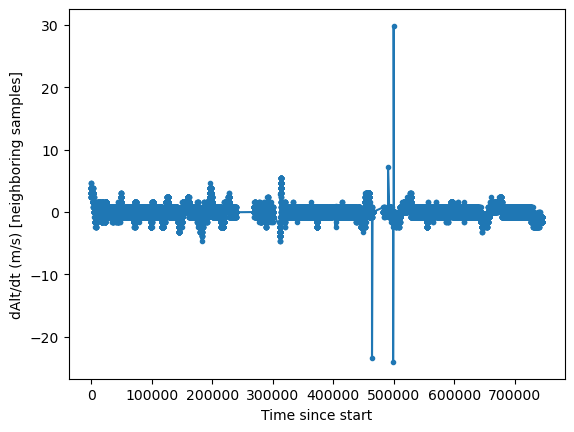

In [16]:
plt.plot((ct - ct[0])[:-1], alt_num_deriv, '.-')

plt.xlabel('Time since start')
plt.ylabel('dAlt/dt (m/s) [neighboring samples]')

plt.show()
plt.close()

In [18]:
# Calculate inner 68 of the distribution of the numerical derivative
median_alt_deriv = np.median(alt_num_deriv)
print('Median dAlt/dt: ', median_alt_deriv)
lo_percent_alt_deriv = np.percentile(alt_num_deriv, 16.)
hi_percent_alt_deriv = np.percentile(alt_num_deriv, 84.)
spread_lo, spread_hi = (median_alt_deriv - lo_percent_alt_deriv, hi_percent_alt_deriv - median_alt_deriv)
print('Approx 1sigma above median: ', spread_lo)
print('Approx 1sigma below median: ', spread_hi)

Median dAlt/dt:  0.0
Approx 1sigma above median:  0.7810000000001309
Approx 1sigma below median:  0.7810000000001309


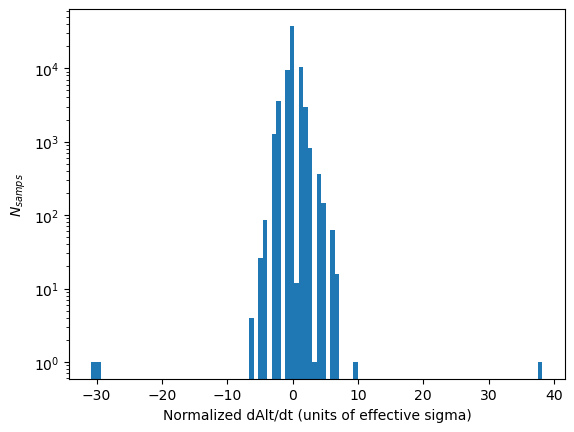

In [20]:
plt.hist((alt_num_deriv - median_alt_deriv)/(0.5*(spread_lo+spread_hi)), bins=100)
plt.yscale('log')

plt.xlabel('Normalized dAlt/dt (units of effective sigma)')
plt.ylabel(r'$N_{samps}$')

plt.show()
plt.close()

In [21]:
# Set outlier cut by eye for now
outliers_alt_deriv = np.logical_or((alt_num_deriv < (median_alt_deriv - 8.5*spread_lo)), 
                                   (alt_num_deriv > (median_alt_deriv + 8.5*spread_hi)))
print(np.sum(outliers_alt_deriv))
print(np.where(outliers_alt_deriv))

4
(array([41465, 41831, 42460, 42498]),)


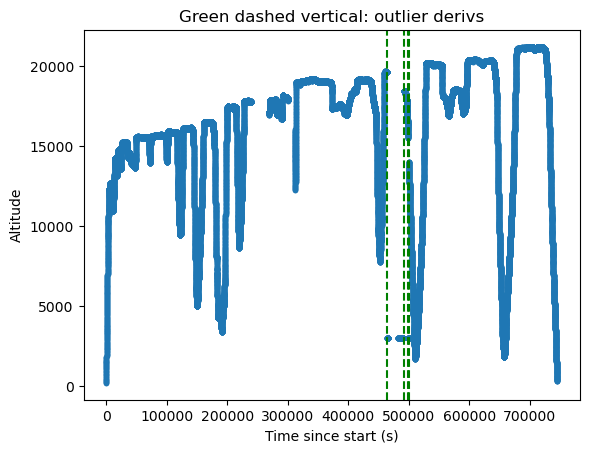

In [22]:
plt.plot(ct - ct[0], alt_vec, '.')
for outlier_ind in np.where(outliers_alt_deriv)[0]:
    plt.axvline(ct[outlier_ind+1] - ct[0], linestyle='dashed', color='g')

#plt.xlim(ct[41450] - ct[0], ct[42525] - ct[0])

plt.xlabel('Time since start (s)')
plt.ylabel('Altitude')

plt.title('Green dashed vertical: outlier derivs')

plt.show()
plt.close()

In [23]:
# Make cuts in pairs -- apparent that large deviations in derivative occur as down then up, or up then down
outlier_inds = np.where(outliers_alt_deriv)[0]

# This assumes the outlier flag caught the pair
assert outlier_inds.size%2 == 0

proposed_alt_cuts = [np.arange(outlier_inds[i]+1, outlier_inds[i+1]+1) for i in np.arange(outlier_inds.size)[::2]]
bad_alt_mask = np.zeros(alt_vec.size)
for l in proposed_alt_cuts:
    bad_alt_mask[l] = 1
bad_alt_mask = bad_alt_mask.astype(np.bool)

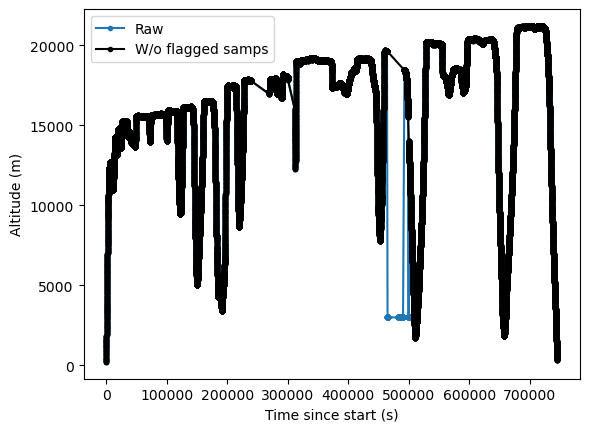

In [24]:
plt.plot(ct - ct[0], alt_vec, '.-', label='Raw')
plt.plot(ct[~bad_alt_mask] - ct[0], alt_vec[~bad_alt_mask], 'k.-', label='W/o flagged samps')

plt.legend()
plt.xlabel('Time since start (s)')
plt.ylabel('Altitude (m)')

plt.show()
plt.close()

In [26]:
# Another approach -- calculate the convolution of the sensor vector with a single-sample step
# Defining a function here as this will be broadly useful
def sensor_step_convolve(sensor_vec, time_vec, step=[-0.5, 0.5], plot=True, labels=['y']):
    stepconv_vec = np.convolve(sensor_vec, step, mode='same')

    plt.figure()
    plt.plot(time_vec - time_vec[0], stepconv_vec, '.')
    plt.xlabel('Time since start (s)')
    plt.ylabel(f'{labels[0]}')

    plt.show()
    
    return stepconv_vec

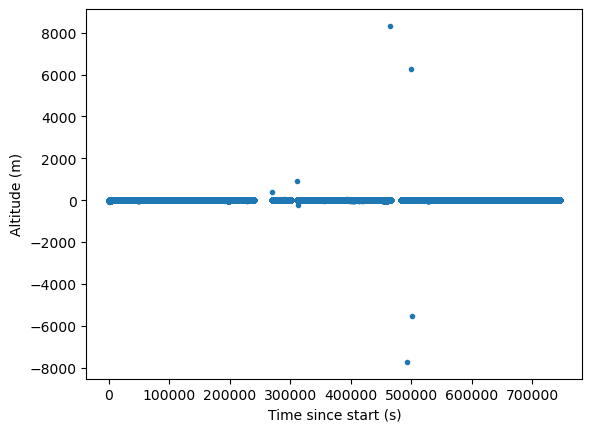

In [29]:
# Run convolution on altitude
stepconv_alt_vec = sensor_step_convolve(alt_vec, ct, labels=['Altitude (m)'])

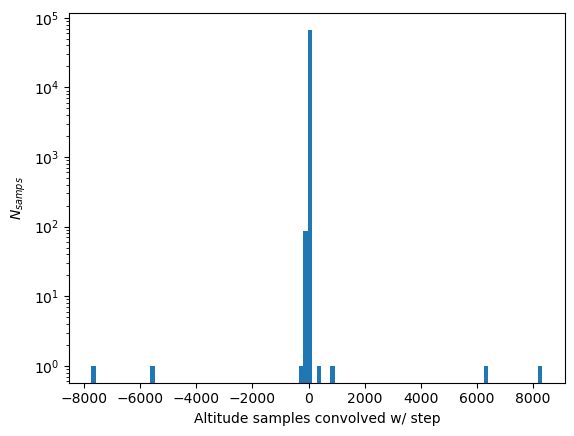

In [33]:
# Simple histogram, looking for outliers
plt.hist(stepconv_alt_vec, bins=100)

plt.yscale('log')
plt.xlabel('Altitude samples convolved w/ step')
plt.ylabel(r'$N_{samps}$')

plt.show()
plt.close()

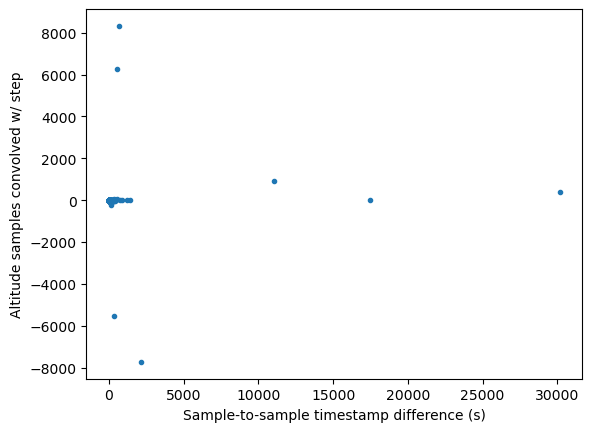

In [112]:
# Clear outliers in the convolution can be compared against long gaps in samples to avoid bias
# Stepwise convolution doesn't know how to distinguish large change between samples due to missing samples
tstamp_sample_diff = np.diff(ct)

plt.plot(tstamp_sample_diff, stepconv_alt_vec[1:], '.')
plt.xlabel('Sample-to-sample timestamp difference (s)')
plt.ylabel('Altitude samples convolved w/ step')

plt.show()
plt.close()

# Outliers are not displaced from normally-sampled data

In [36]:
# How many samples above a threshold of 300, for example?
np.sum(np.abs(stepconv_alt_vec) > 300)

np.int64(6)

In [37]:
# Define a new function for pairing step-like sample indices based on sign change of step convolution
# Alternately, don't ask for pairs and just get step-convolved sample indices above threshold
def find_steplike_inds(stepconv_val, threshold, find_pairs=False):
    steplike_inds = np.where(np.abs(stepconv_val) > threshold)[0]
    if find_pairs:
        paired_steplike_inds = [(steplike_inds[i], steplike_inds[i+1]) for i in range(steplike_inds.size-1) 
                                if np.sign(stepconv_val[steplike_inds[i]]) != np.sign(stepconv_val[steplike_inds[i+1]])][::2]
        unpaired_steplike_inds = [steplike_inds[i] for i in range(steplike_inds.size-1) 
                                  if np.sign(stepconv_val[steplike_inds[i]]) == np.sign(stepconv_val[steplike_inds[i+1]])]

        return paired_steplike_inds, unpaired_steplike_inds

    else:
        return steplike_inds

In [38]:
paired_steplike_inds_alt, unpaired_steplike_inds_alt = find_steplike_inds(stepconv_alt_vec, 300., find_pairs=True)

In [39]:
paired_steplike_inds_alt

[(np.int64(41466), np.int64(41832)), (np.int64(42461), np.int64(42499))]

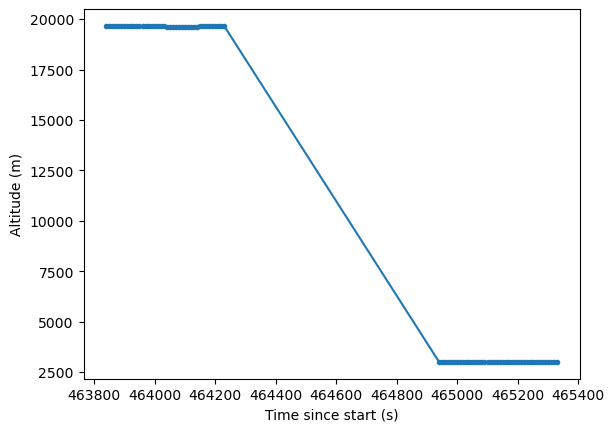

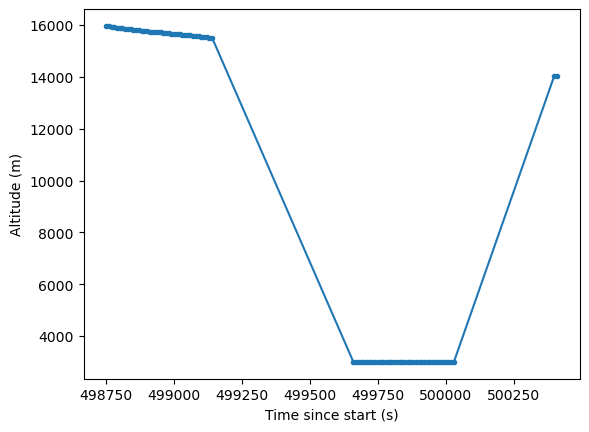

In [42]:
# Look at samples in region around start of pair
for i in paired_steplike_inds_alt:
    i = i[0]
    plt.figure()
    plt.plot(ct[i-40:i+40] - ct[0], alt_vec[i-40:i+40], '.-')
    plt.xlabel('Time since start (s)')
    plt.ylabel('Altitude (m)')

plt.show()
plt.close()

# First plot shows that period with near static values lower than expected is longer than 40 samples

In [44]:
# Calculate mask similarly to outliers found via num derivative
proposed_alt_cuts_v2 = [np.arange(paired_steplike_inds_alt[i][0], paired_steplike_inds_alt[i][1]) for i in np.arange(len(paired_steplike_inds_alt))]
bad_alt_mask_v2 = np.zeros(alt_vec.size)
for l in proposed_alt_cuts_v2:
    bad_alt_mask_v2[l] = 1
bad_alt_mask_v2 = bad_alt_mask_v2.astype(np.bool)

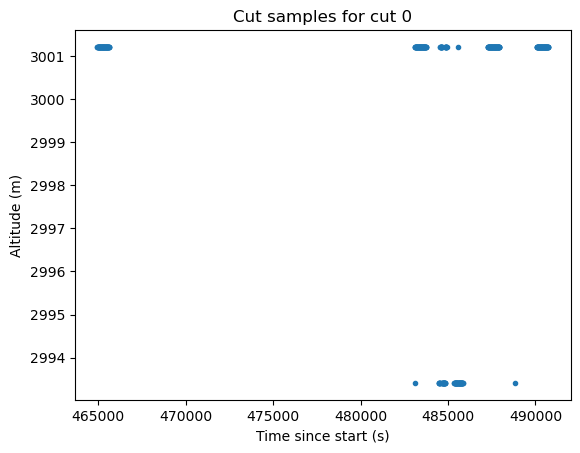

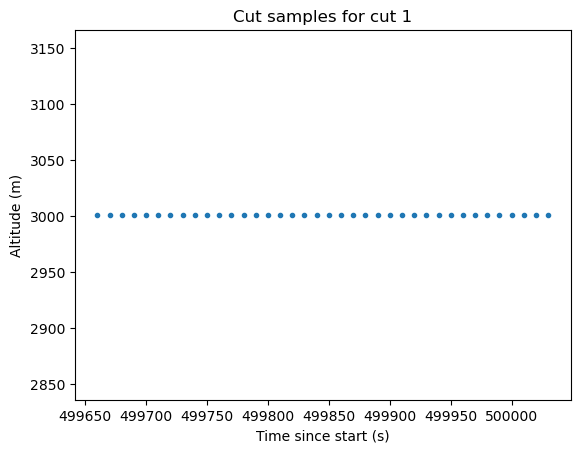

In [48]:
# What do cut samples look like
for q,pcut in enumerate(proposed_alt_cuts_v2):
    plt.figure()
    plt.plot(ct[pcut] - ct[0], alt_vec[pcut], '.')
    plt.xlabel('Time since start (s)')
    plt.ylabel('Altitude (m)')
    plt.title(f'Cut samples for cut {q}')

plt.show()
plt.close()
# Second look extremely unphysical, no noise; 
# first set possibly consistent with a targeted drop over 10 mins,
# but numerical derivative tells us these would be strong outliers still in terms of a rise/fall even with missing samples

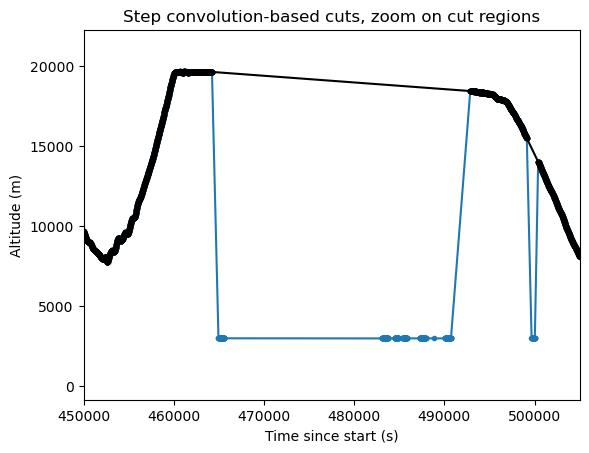

In [49]:
plt.plot(ct - ct[0], alt_vec, '.-', label='Raw')
plt.plot(ct[~bad_alt_mask_v2] - ct[0], alt_vec[~bad_alt_mask_v2], 'k.-', label='W/o flagged samps')
plt.title('Step convolution-based cuts, zoom on cut regions')
plt.xlabel('Time since start (s)')
plt.ylabel('Altitude (m)')

plt.xlim(450000, 505000)

plt.show()
plt.close()

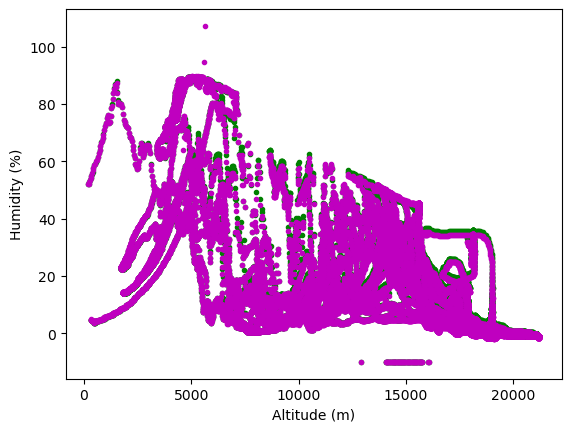

In [50]:
# quick check -- any strong global correlations between humidity and altitude after altitude cuts?

plt.plot(alt_vec[~bad_alt_mask_v2], h1_vec[~bad_alt_mask_v2], 'g.', label='H1')
plt.plot(alt_vec[~bad_alt_mask_v2], h2_vec[~bad_alt_mask_v2], 'm.', label='H2')
plt.xlabel('Altitude (m)')
plt.ylabel('Humidity (%)')

plt.show()
plt.close()

# Not really!

In [53]:
# Clearly some samples are negative & unphysical -- find those
# Expect they may cause unusual deviations due to sensor fault
h2_neg_samples = (h2_vec < 0.)
h1_neg_samples = (h1_vec < 0.)

In [54]:
print(np.sum(h2_neg_samples))
print(np.sum(h1_neg_samples))
print(np.sum(h1_neg_samples*h2_neg_samples)) # safe to assume all h1_neg samples are also h2_neg, these are "common_neg"

17291
14566
14566


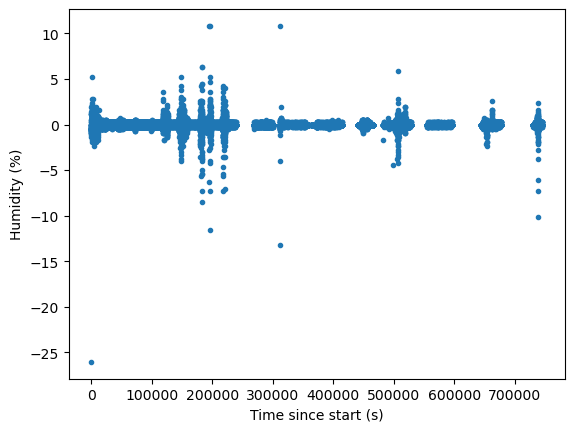

In [88]:
# Jump convolution for h2
stepconv_h2_vec = sensor_step_convolve(h2_vec[~h2_neg_samples], ct[~h2_neg_samples] - ct[0], labels=['Humidity (%)'])

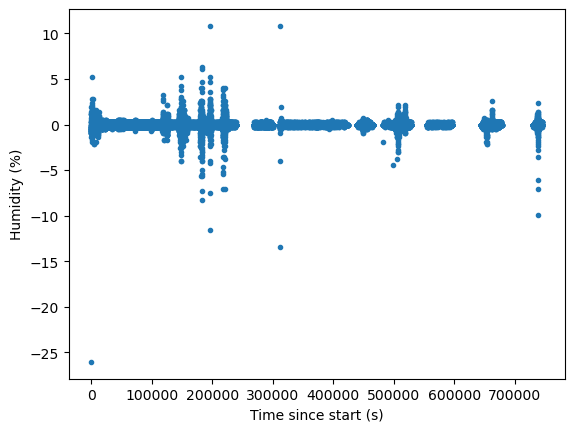

In [58]:
# Jump convolution for h1
stepconv_h1_vec = sensor_step_convolve(h1_vec[~h1_neg_samples], ct[~h1_neg_samples] - ct[0], labels=['Humidity (%)'])

In [60]:
# Based only on quick visual inspection, return all points with convolutions to step > 10
unpair_inds_h2 = find_steplike_inds(stepconv_h2_vec, 10)
unpair_inds_h1 = find_steplike_inds(stepconv_h1_vec, 10)

In [63]:
# Are these values at the same times?
unpair_times_h1 = np.array([ct[i] - ct[0] for i in unpair_inds_h1])
print('Time of steps H1: ', unpair_times_h1)
#print(unpair_inds_h1)
unpair_times_h2 = np.array([ct[i] - ct[0] for i in unpair_inds_h2])
print('Time of steps H2: ', unpair_times_h2)
#print(unpair_inds_h2)

# All except 2 are common

Time of steps H1:  [     0. 196230. 196430. 311600. 311610.]
Time of steps H2:  [     0. 194940. 196230. 196430. 311600. 311610. 566420.]


In [64]:
# Get only those point-like steps for each humidity sensor that are not present in the other
unique_excursion_h1 = [ind for i,ind in enumerate(unpair_inds_h1) if unpair_times_h1[i] not in unpair_times_h2]
unique_excursion_h2 = [ind for i,ind in enumerate(unpair_inds_h2) if unpair_times_h2[i] not in unpair_times_h1]

In [65]:
print(unique_excursion_h1)
print(unique_excursion_h2)

[]
[np.int64(19487), np.int64(49089)]


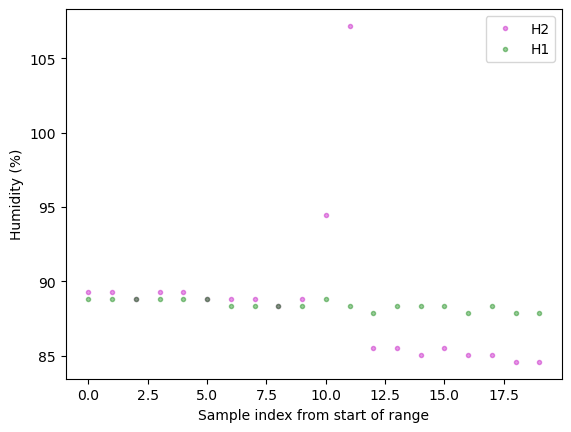

In [81]:
# First example of H2 deviating from H1
ind_range = np.arange(19475, 19495)
plt.plot(h2_vec[ind_range], 'm.', alpha=0.4, label='H2')
plt.plot(h1_vec[ind_range], 'g.', alpha=0.4, label='H1')
plt.legend()
plt.xlabel('Sample index from start of range')
plt.ylabel('Humidity (%)')

plt.show()
plt.close()

In [74]:
# Begin patching H2 bad values with H1 values
common_neg_flags = (h1_neg_samples) * (h2_neg_samples)

# Flagging sample regions that are problematic in H2, not in H1
diff_excursion_flag_inds_h2 = [np.arange(flag-3, flag+3) for flag in unique_excursion_h2]
diff_excursion_flags_h2 = np.zeros(h2_vec.size)
for l in diff_excursion_flag_inds_h2:
    diff_excursion_flags_h2[l] = 1

# For symmetry, though there are no examples, doing vice versa
diff_excursion_flag_inds_h1 = [np.arange(flag-3, flag+3) for flag in unique_excursion_h1]
diff_excursion_flags_h1 = np.zeros(h1_vec.size)
for l in diff_excursion_flag_inds_h1:
    diff_excursion_flags_h1[l] = 1

In [71]:
# fill H2 with h1
h2_distinct_neg_flags = ~common_neg_flags * h2_neg_samples
h2_fill_flags = np.logical_or(h2_distinct_neg_flags, diff_excursion_flags_h2.astype(bool))

h2_vec_mod = h2_vec.copy()
h2_vec_mod[h2_fill_flags] = h1_vec[h2_fill_flags]

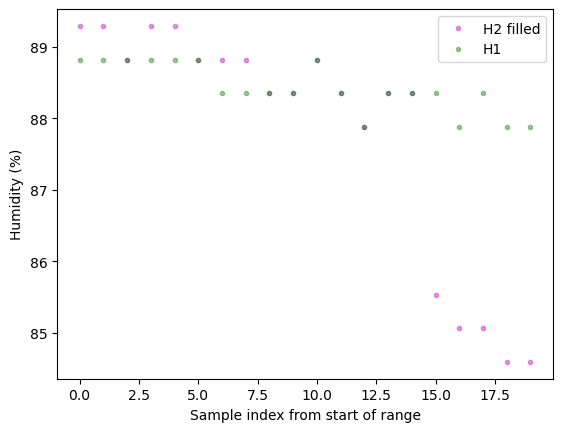

In [80]:
# Check fill at example deviation
ind_range = np.arange(19475, 19495)
plt.plot(h2_vec_mod[ind_range], 'm.', alpha=0.4, label='H2 filled')
plt.plot(h1_vec[ind_range], 'g.', alpha=0.4, label='H1')
plt.legend()
plt.xlabel('Sample index from start of range')
plt.ylabel('Humidity (%)')

plt.show()
plt.close()

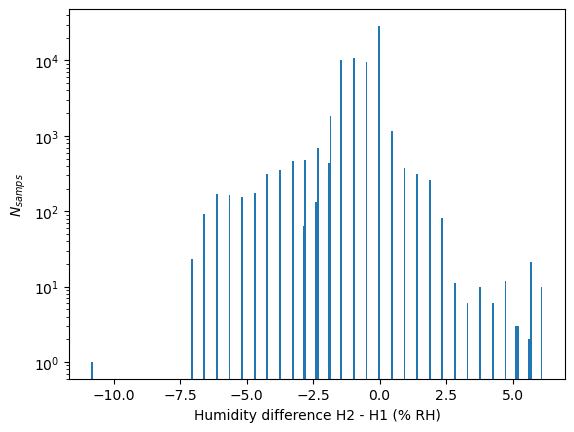

In [75]:
# Quick sanity check on typical deviation of H2 filled & H1
plt.hist(h2_vec_mod - h1_vec, bins=250)
plt.yscale('log')
plt.xlabel('Humidity difference H2 - H1 (% RH)')
plt.ylabel(r'$N_{samps}$')

plt.show()
plt.close()
# Difference at 10 = outlier?

In [76]:
humidity_difference_outlier_ind = np.where(np.abs(h2_vec_mod - h1_vec) > 7.5)[0]
print(humidity_difference_outlier_ind)

[43245]


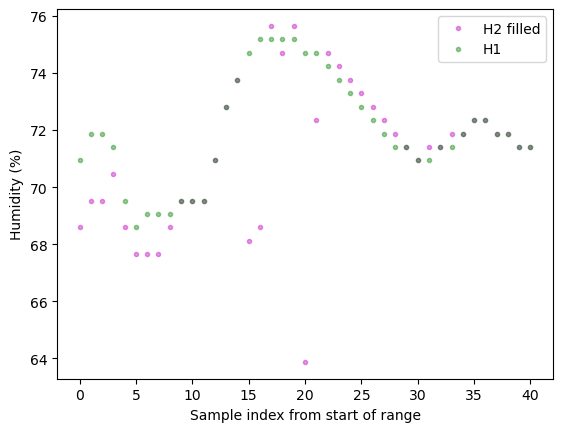

In [79]:
# Examine region around deviation
ind_range = np.arange(humidity_difference_outlier_ind[0] - 20, humidity_difference_outlier_ind[0] + 21)
plt.plot(h2_vec_mod[ind_range], 'm.', alpha=0.4, label='H2 filled')
plt.plot(h1_vec[ind_range], 'g.', alpha=0.4, label='H1')
plt.legend()
plt.xlabel('Sample index from start of range')
plt.ylabel('Humidity (%)')

plt.show()
plt.close()
# Appears that this was only ~5 in terms of convolution to step, but not present in H1

In [82]:
# Fill outlier deviation of H2 from H1 with H1 value
h2_vec_mod[humidity_difference_outlier_ind] = h1_vec[humidity_difference_outlier_ind]

In [83]:
h_vec = 0.5*(h2_vec_mod + h1_vec)

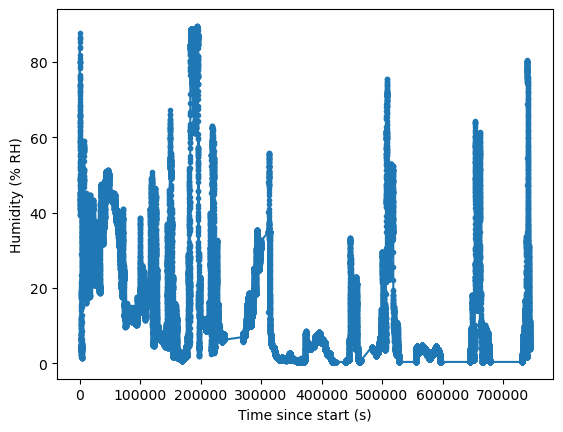

In [85]:
# Quick timestream check of averaged vector
plt.plot(ct[~common_neg_flags] - ct[0], h_vec[~common_neg_flags], '.-')
plt.xlabel('Time since start (s)')
plt.ylabel('Humidity (% RH)')

plt.show()
plt.close()

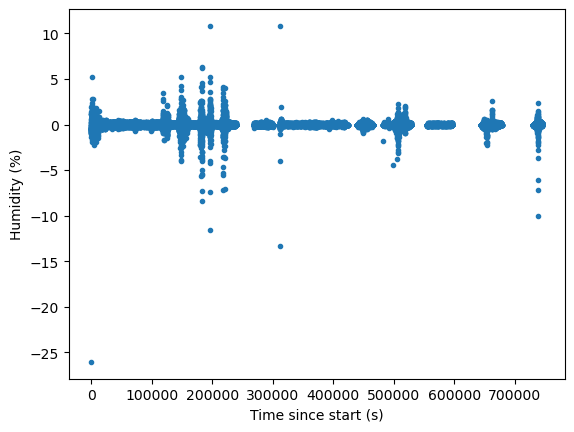

In [87]:
stepconv_h_vec = sensor_step_convolve(h_vec[~common_neg_flags], ct[~common_neg_flags] - ct[0], labels=['Humidity (%)'])
# Avoid possible jump like behavior near places where both average is negative

In [89]:
unpair_inds_h = find_steplike_inds(stepconv_h_vec, 10.) # same threshold as before
print(unpair_inds_h)

[    0 19616 19636 26952 26953 51814]


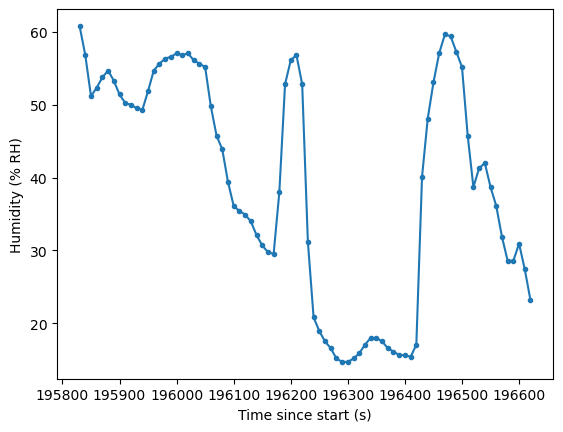

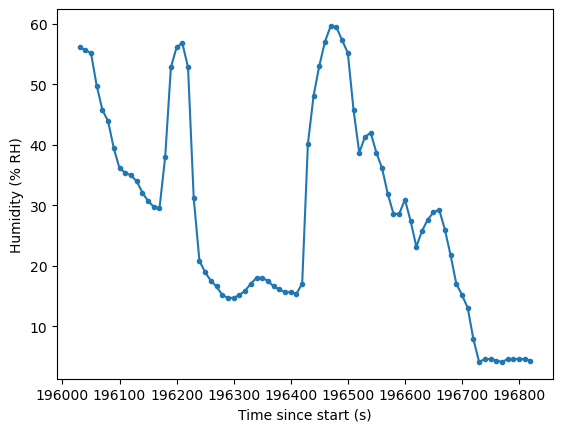

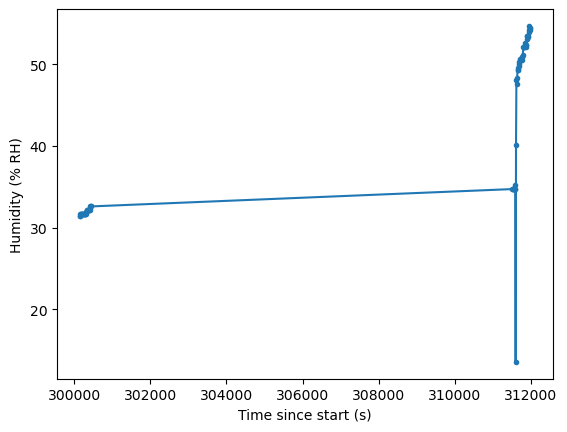

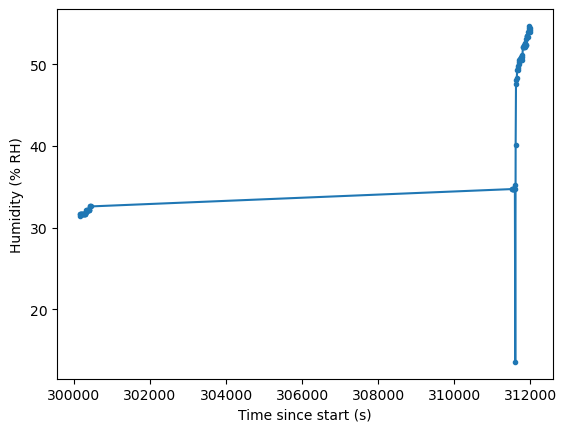

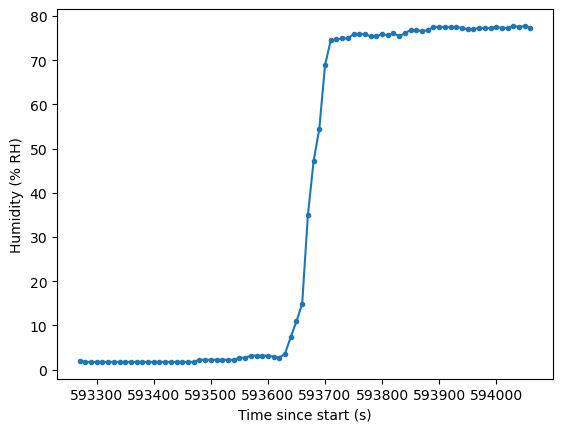

In [90]:
# For each of these blips, let's plot the timestream
for i in unpair_inds_h[1:]:
    if np.any(bad_alt_mask_v2[~common_neg_flags][i-40:i+40]):
        continue
    plt.figure()
    plt.plot(ct[i-40:i+40] - ct[0], h_vec[~common_neg_flags][i-40:i+40], '.-')
    plt.xlabel('Time since start (s)')
    plt.ylabel('Humidity (% RH)')

plt.show()
plt.close()

# Some are near big gaps, others look physical

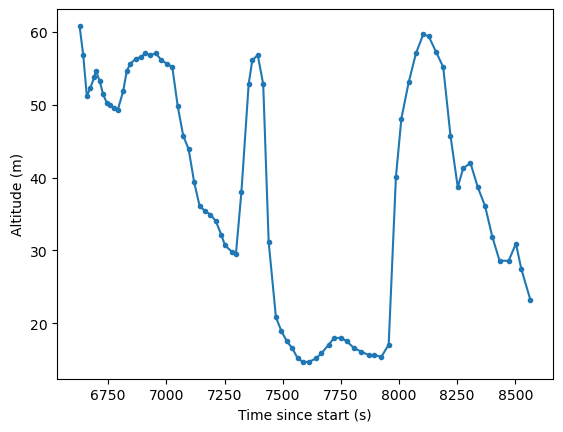

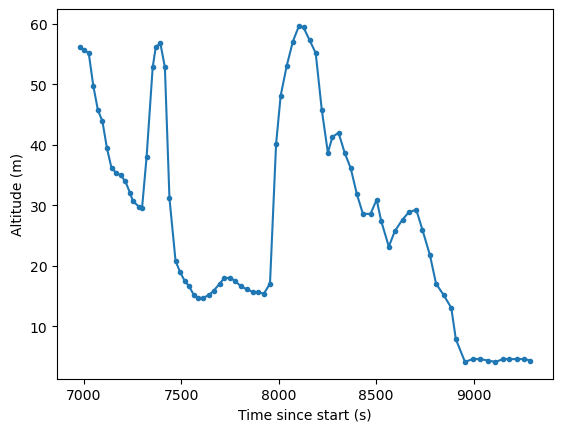

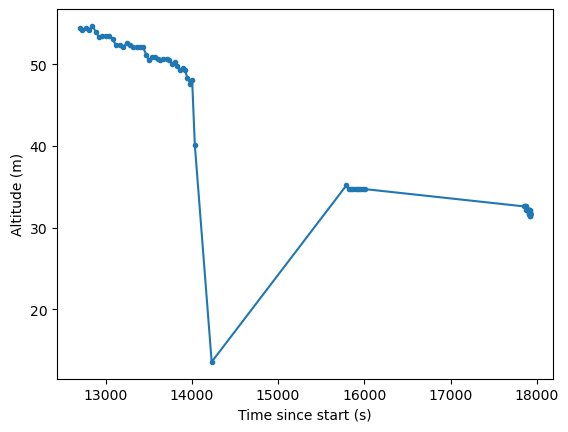

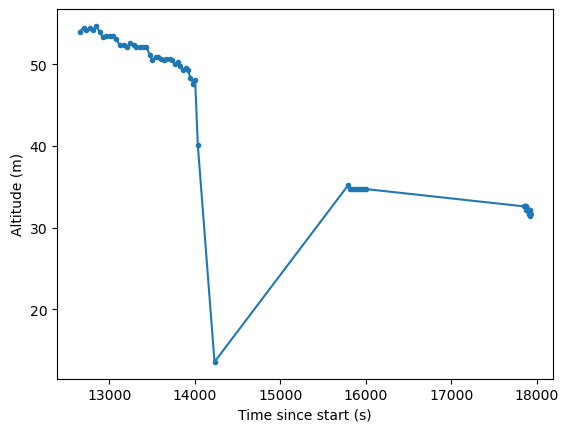

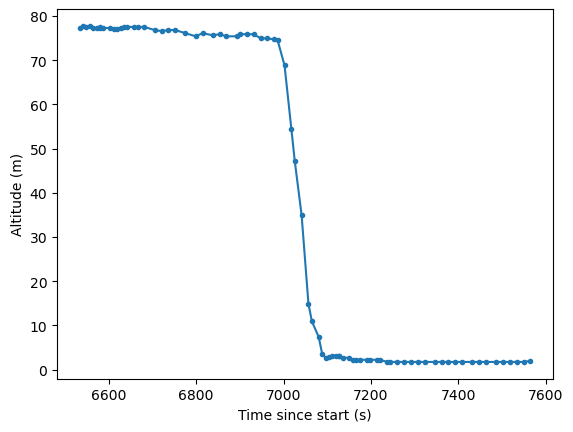

In [92]:
# What about vs altitude?
for i in unpair_inds_h[1:]:
    if np.any(bad_alt_mask_v2[~common_neg_flags][i-40:i+40]):
        continue
    plt.figure()
    plt.plot(alt_vec[~common_neg_flags][i-40:i+40], h_vec[~common_neg_flags][i-40:i+40], '.-')
    plt.xlabel('Time since start (s)')
    plt.ylabel('Altitude (m)')

plt.show()
plt.close()
# Truly point-like glitch appearances are all at high altitude

In [93]:
# Create flags for combined humidity vector that only catches point-like glitch
bad_step_conv_flag_inds_h = [i for i in unpair_inds_h if alt_vec[~common_neg_flags][i] > 12.e3] 

In [94]:
bad_step_conv_flag_inds_h

[np.int64(26952), np.int64(26953)]

In [291]:
# Also cut the negative samples -- how many are there?
np.sum(common_neg_flags)

np.int64(14566)

In [95]:
# Combine common_neg_flags and the two combined-vector glitches
bad_h_mask = common_neg_flags.copy()
print(bad_h_mask.size, ct.size)
for i in bad_step_conv_flag_inds_h:
    bad_h_mask[np.where(~common_neg_flags)[0][i]] = 1
print(np.sum(bad_h_mask))

66982 66982
14568


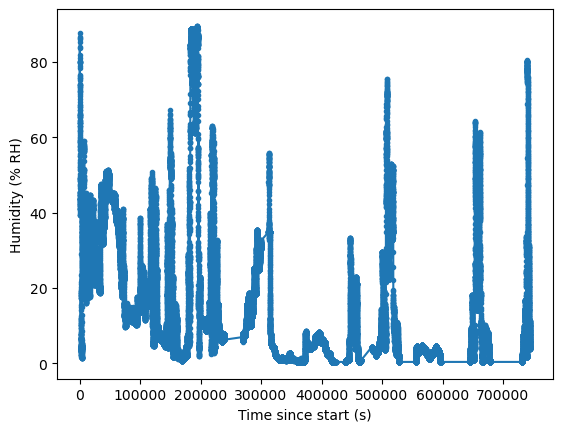

In [97]:
# Sanity check of whole timestream
plt.plot(ct[~bad_h_mask] - ct[0], h_vec[~bad_h_mask], '.-')
plt.xlabel('Time since start (s)')
plt.ylabel('Humidity (% RH)')

plt.show()
plt.close()

In [99]:
# Found unphysical jumps in temp vector seemingly due to temperature being at low end of range reading
# Flagging before estimating jumps
temp_range = [np.amin(temp_vec), np.amax(temp_vec)]
print('Low and high rails (C) for temp sensor: ', temp_range)
print('Sample counts for low rail - high rail: ', [np.sum(temp_vec == tr) for tr in temp_range])

# Making mask to remove these from step estimation
temp_outrange_mask = np.zeros(temp_vec.size).astype(np.bool)
temp_outrange_mask[np.logical_or((temp_vec == temp_range[0]), (temp_vec == temp_range[1]))] = 1

Low and high rails (C) for temp sensor:  [np.float64(-88.9), np.float64(48.9)]
Sample counts for low rail - high rail:  [np.int64(131), np.int64(7)]


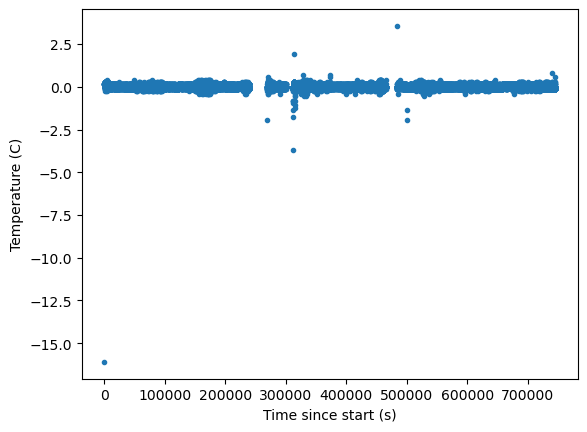

In [100]:
stepconv_temp_vec_masked = sensor_step_convolve(temp_vec[~temp_outrange_mask], ct[~temp_outrange_mask] - ct[0], labels=['Temperature (C)'])

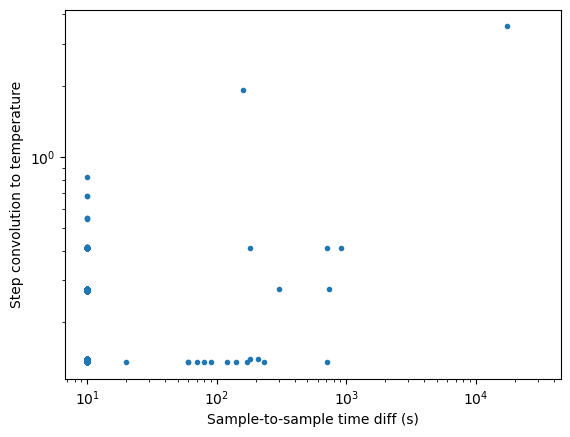

In [113]:
# Looking in 2D space again for dependence of large step convolution values & next-sample time difference 
plt.loglog(np.diff(ct[~temp_outrange_mask]), stepconv_temp_vec_masked[1:], '.')
plt.xlabel('Sample-to-sample time diff (s)')
plt.ylabel('Step convolution to temperature')

plt.show()
plt.close()
# Largest steps consistent with large gap of tens of samples -- few hundred s

In [102]:
# 2D cut -- focus on upper left of figure above
questionable_samples = np.where((np.diff(ct[~temp_outrange_mask]) < 20.) * (stepconv_temp_vec_masked[:-1] > 0.5))[0]
print(questionable_samples)

[24052 26938 28460 32743 32744 41396 66242 66839]


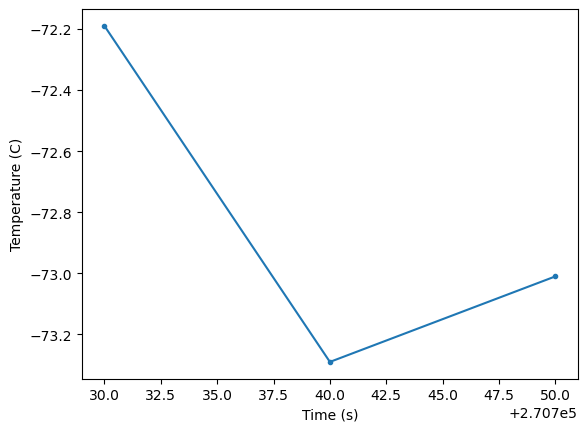

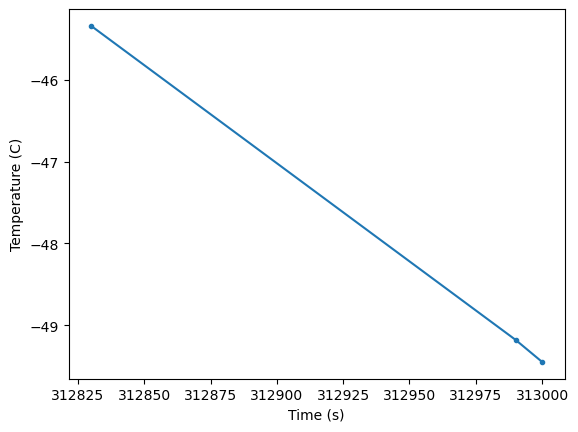

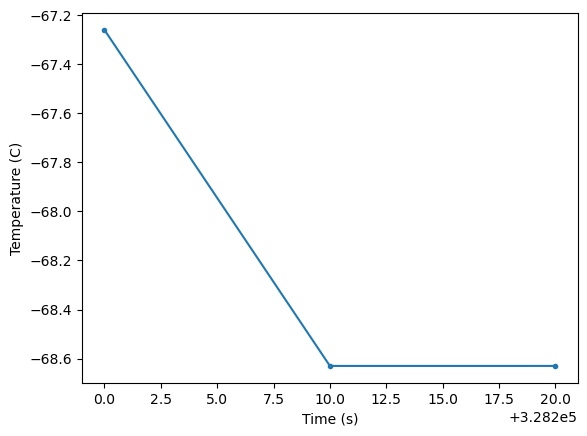

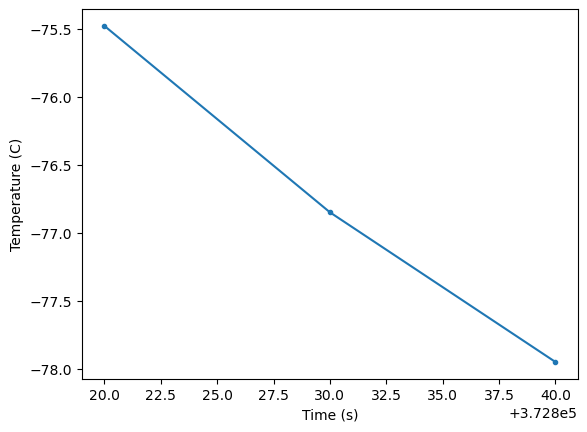

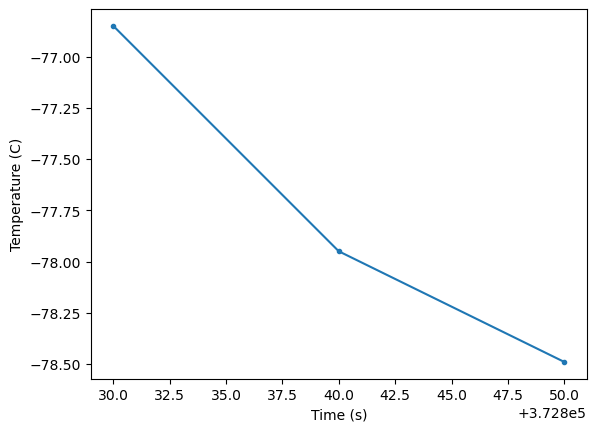

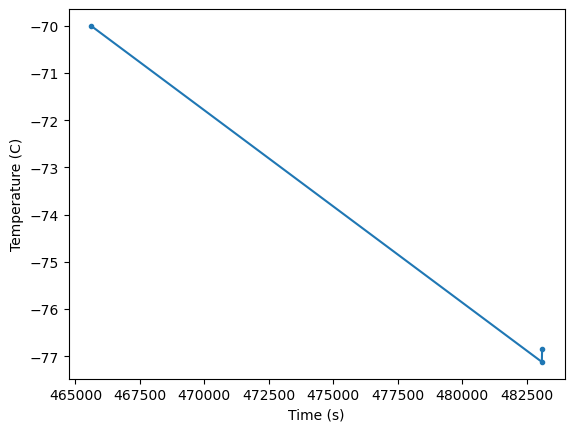

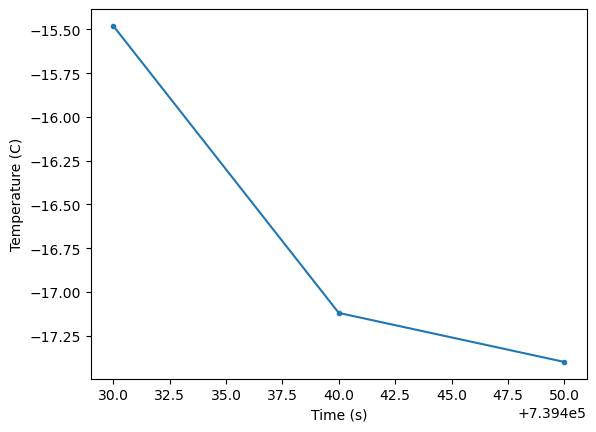

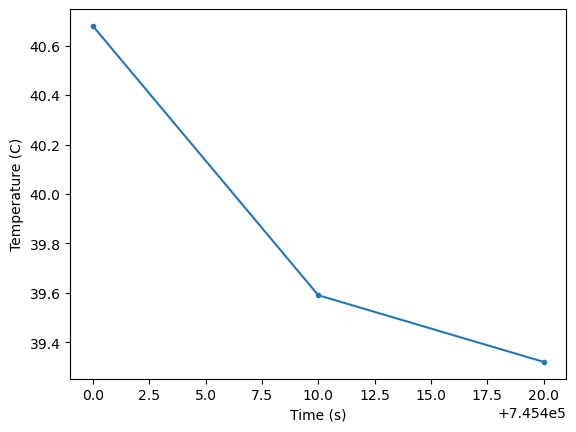

In [103]:
for i in questionable_samples:
    ind_range = np.arange(i-1, i+2)
    plt.figure()
    plt.plot(ct[~temp_outrange_mask][ind_range] - ct[0], temp_vec[~temp_outrange_mask][ind_range], '.-')
    plt.xlabel('Time (s)')
    plt.ylabel('Temperature (C)')

plt.show()
plt.close()
# Nothing too crazy here!

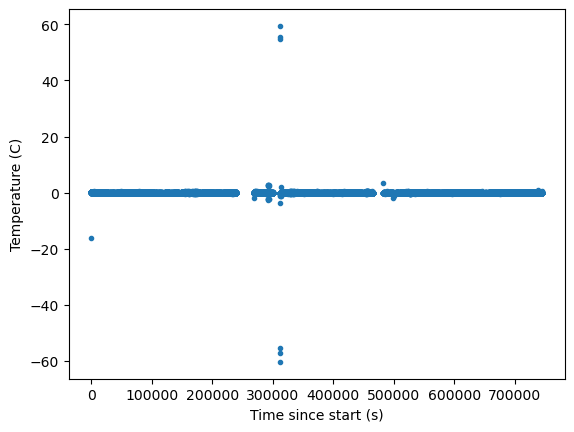

In [104]:
# No clear steps after removing railed values
## Trying without cut
stepconv_temp_vec = sensor_step_convolve(temp_vec, ct, labels=['Temperature (C)'])

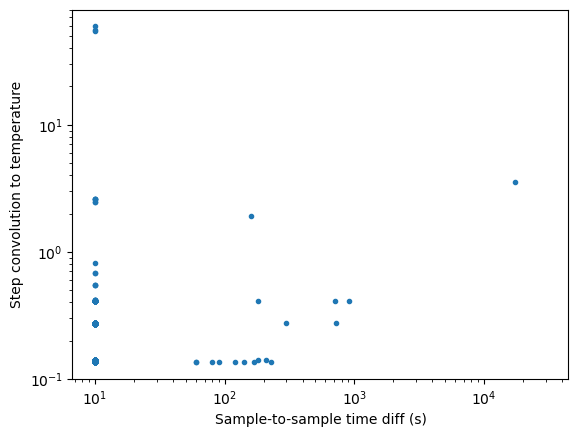

In [109]:
# Same 2D space as before
plt.loglog(np.diff(ct), stepconv_temp_vec[1:], '.')
plt.xlabel('Sample-to-sample time diff (s)')
plt.ylabel('Step convolution to temperature')

plt.show()
plt.close()

In [106]:
# Attempted 2D cut, to be ignored
#pair_inds_temp, unpair_inds_temp = find_steplike_inds(stepconv_temp_vec, 2.5, find_pairs=True)
#print(pair_inds_temp)
#print(unpair_inds_temp)

unpair_inds_temp = find_steplike_inds(stepconv_temp_vec, 2., find_pairs=False)
print([ct[i] - ct[0] for i in unpair_inds_temp])
# Lots of single-point glitch candidates

[np.float64(0.0), np.float64(291560.0), np.float64(291950.0), np.float64(292040.0), np.float64(292740.0), np.float64(292920.0), np.float64(293060.0), np.float64(293090.0), np.float64(293100.0), np.float64(293140.0), np.float64(293200.0), np.float64(293210.0), np.float64(293270.0), np.float64(311510.0), np.float64(311770.0), np.float64(311820.0), np.float64(312240.0), np.float64(312250.0), np.float64(312320.0), np.float64(312330.0), np.float64(483090.0)]


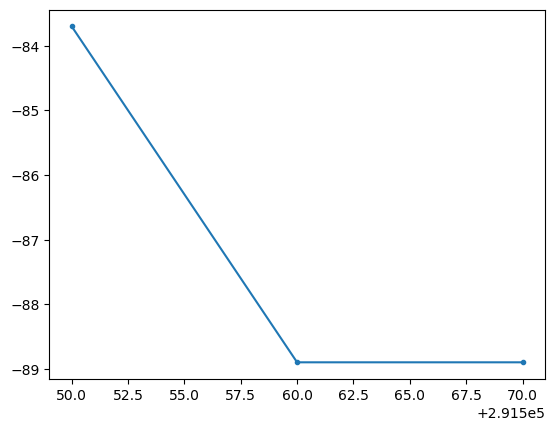

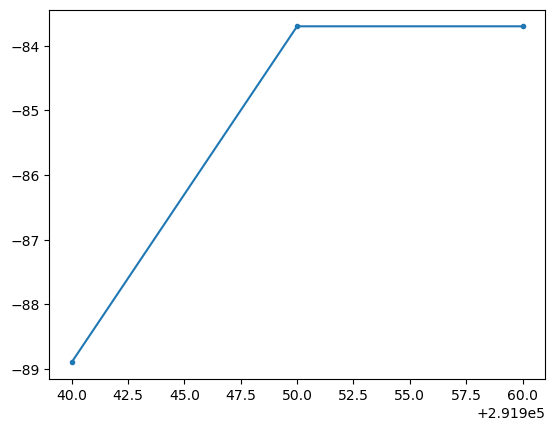

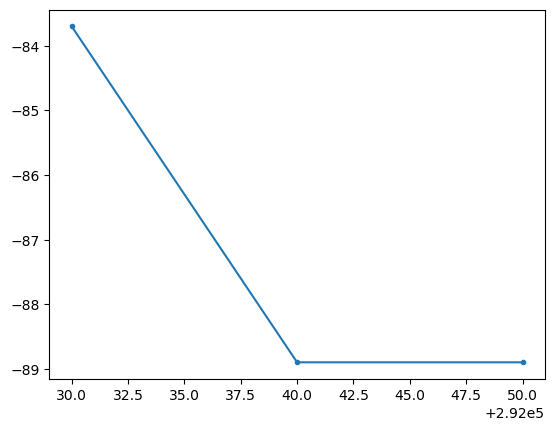

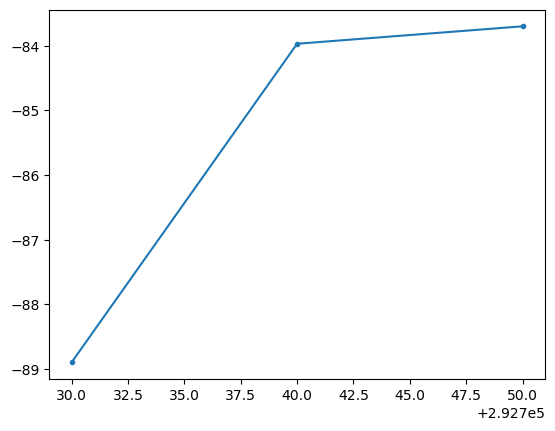

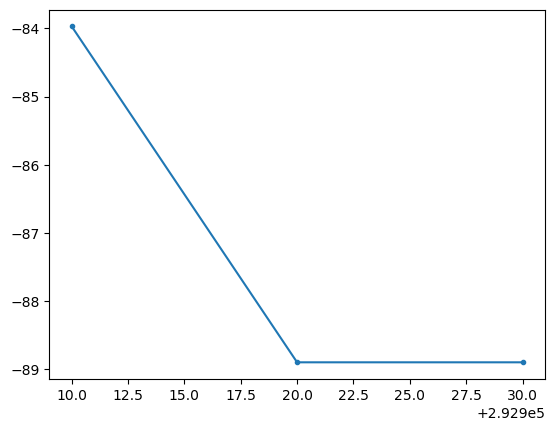

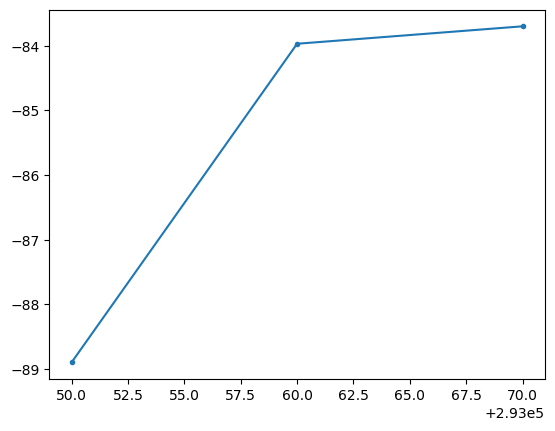

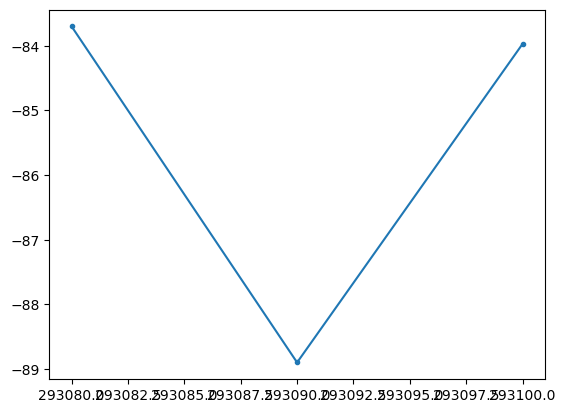

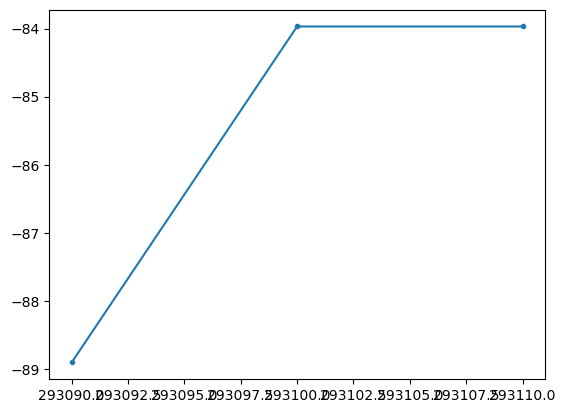

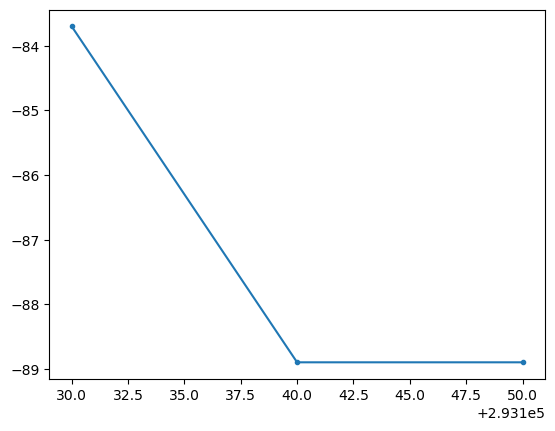

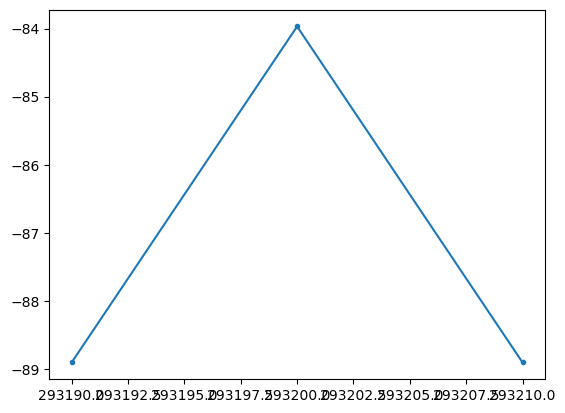

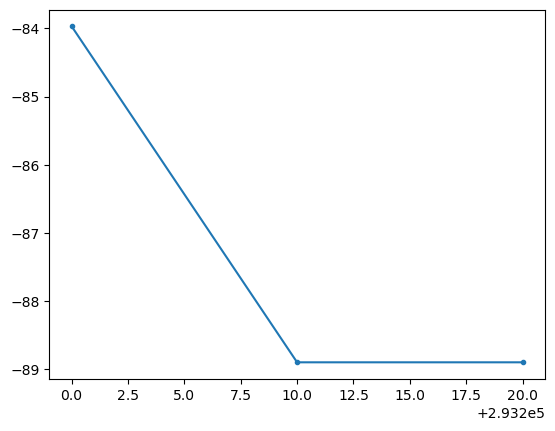

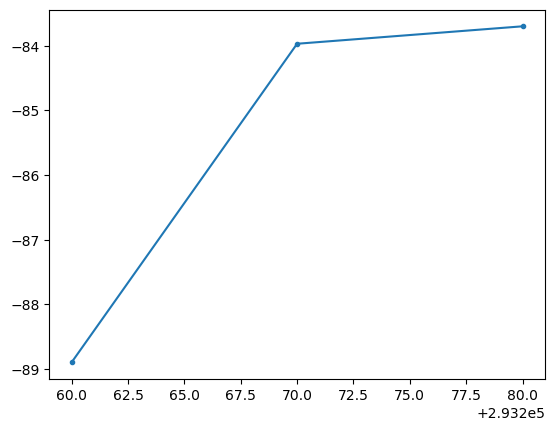

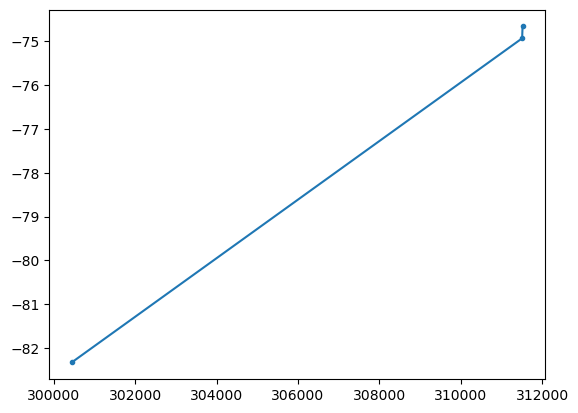

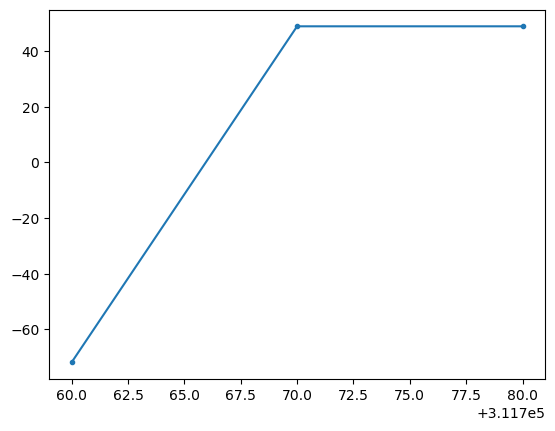

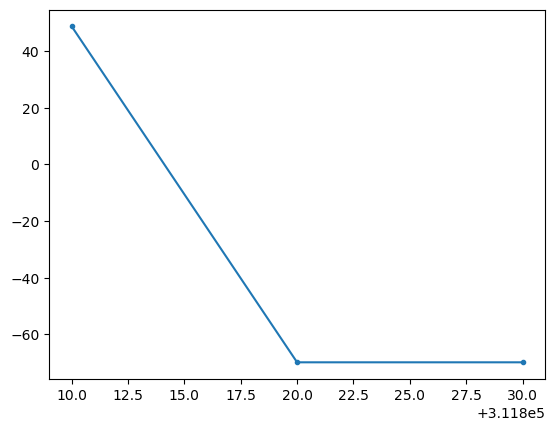

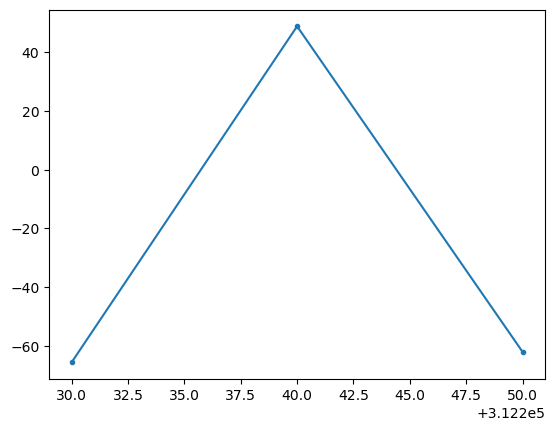

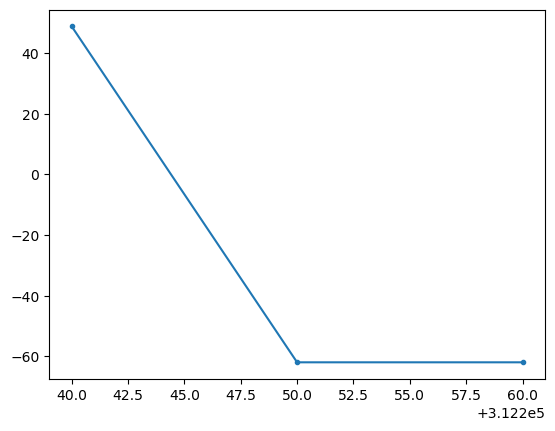

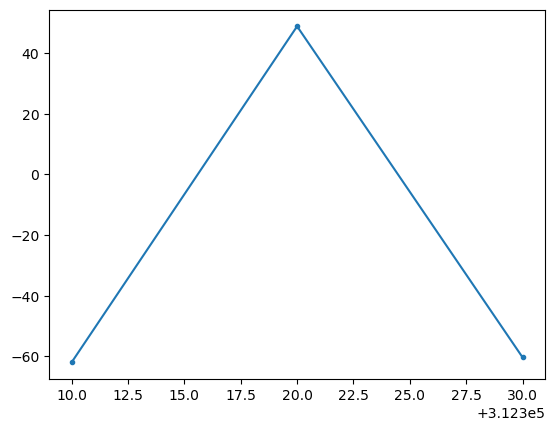

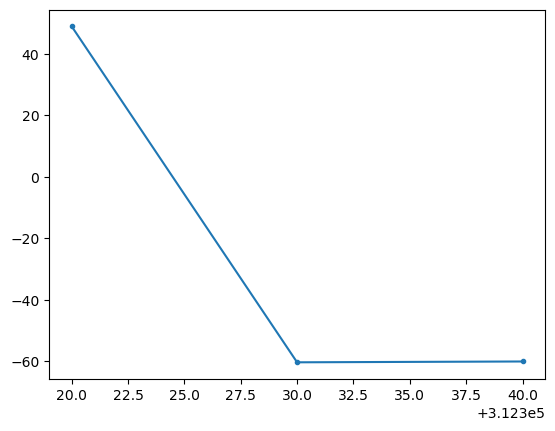

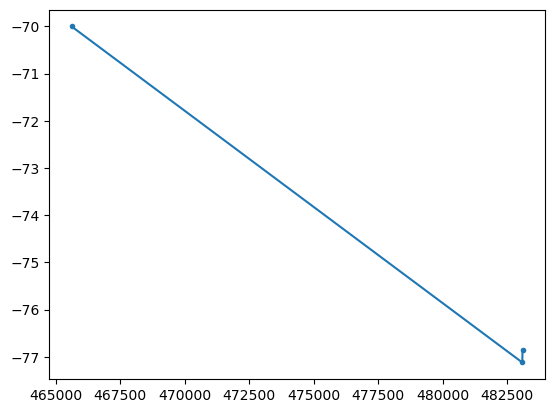

In [116]:
# All of these jumps are the thermometer hitting its limit, either for one sample or several, and can be ignored
# Except for 2 on with long sample gaps just before step -- believe these can be ignored
for i in unpair_inds_temp[1:]:
    ind_range = np.arange(i-1, i+2)
    #if np.any(temp_outrange_mask[ind_range]):
    #    continue
    plt.figure()
    plt.plot(ct[ind_range] - ct[0], temp_vec[ind_range], '.-')

plt.show()
plt.close()

In [117]:
# Simple mask -- just flag railed temperature values
bad_temp_mask = temp_outrange_mask

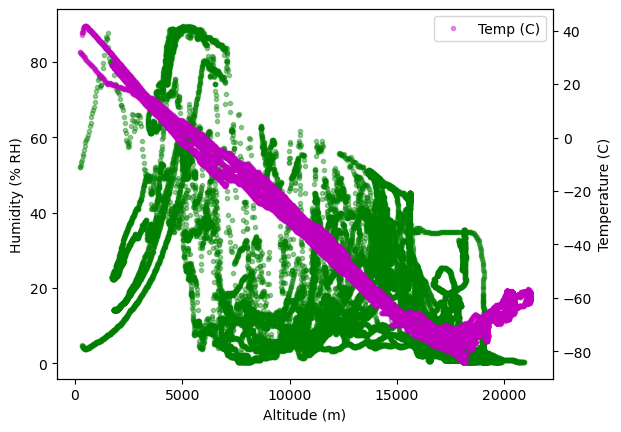

In [119]:
# Comparing temperature vs. altitude and humidity vs. altitude after joint flags applied
plt.plot(alt_vec[~bad_alt_mask_v2*~bad_h_mask], h_vec[~bad_alt_mask_v2*~bad_h_mask], 'g.', alpha=0.4)
plt.xlabel('Altitude (m)')
plt.ylabel('Humidity (% RH)')
ax = plt.twinx()
ax.plot(alt_vec[~bad_alt_mask_v2*~bad_temp_mask], temp_vec[~bad_alt_mask_v2*~bad_temp_mask], 'm.', label='Temp (C)', alpha=0.4)
#ax.plot(alt_vec[~bad_alt_mask_v2], temp_vec[~bad_alt_mask_v2], 'm.', alpha=0.4)
ax.set_ylabel('Temperature (C)')
ax.legend()

plt.show()
plt.close()
# Clear correlation with some noise, stronger variance at low altitude / high temp
# Could be useful for flagging unusual non-railed samples!

In [120]:
# Cut summary on all equal-sampled vectors
print('Sum of samples cut in altitude mask', np.sum(bad_alt_mask_v2))
print('Sum of samples cut in combined humidity mask', np.sum(bad_h_mask))
print('Sum of samples cut in temp mask', np.sum(bad_temp_mask))
print('Sum of samples cut in intersecting flags', np.sum(~(~bad_alt_mask_v2 * ~bad_h_mask * ~bad_temp_mask)))

Sum of samples cut in altitude mask 404
Sum of samples cut in combined humidity mask 14568
Sum of samples cut in temp mask 138
Sum of samples cut in intersecting flags 15103


In [121]:
# Interpolate alt to slower samples
pressure_ctime = sensor_dict['pressure'][:,0]
pressure_vec = sensor_dict['pressure'][:,1]

alt_vec_interp = np.interp(pressure_ctime, ct[~bad_alt_mask_v2], alt_vec[~bad_alt_mask_v2])

In [122]:
# Calc poly
pressure_poly = np.polyfit(alt_vec_interp, pressure_vec, 4)
print('Polynomial parameters', pressure_poly)

pressure_model = np.polyval(pressure_poly, alt_vec_interp)
pressure_residual = pressure_vec - pressure_model

Polynomial parameters [ 1.83995746e-13 -1.45022162e-08  5.51005578e-04 -1.14788716e+01
  1.01607337e+05]


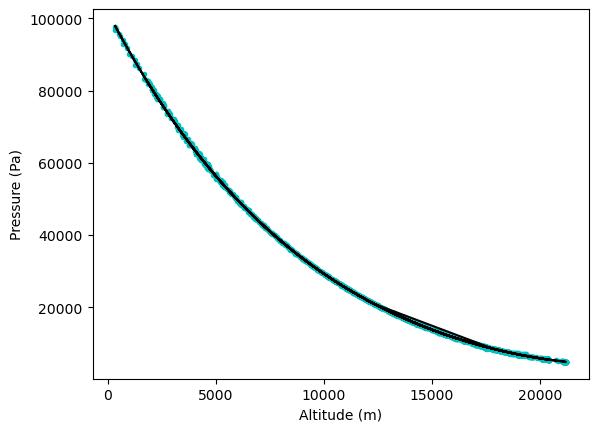

In [123]:
plt.plot(alt_vec_interp, pressure_vec, 'c.', label='Data')
# Plot model line
plt.plot(alt_vec_interp, pressure_model, 'k-', label='Model')
plt.xlabel('Altitude (m)')
plt.ylabel('Pressure (Pa)')

plt.show()
plt.close()

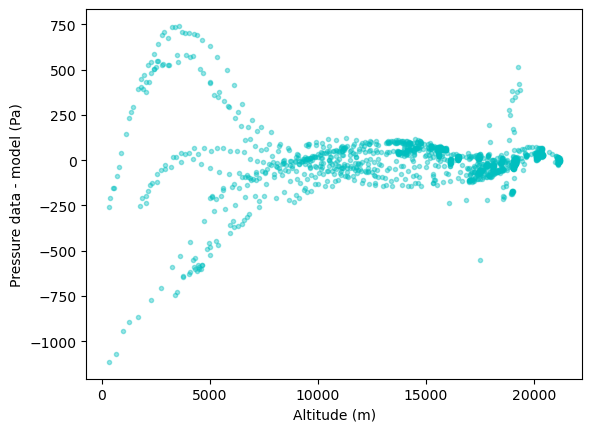

In [124]:
plt.plot(alt_vec_interp, pressure_residual, 'c.', alpha=0.4)
plt.xlabel('Altitude (m)')
plt.ylabel('Pressure data - model (Pa)')

plt.show()
plt.close()

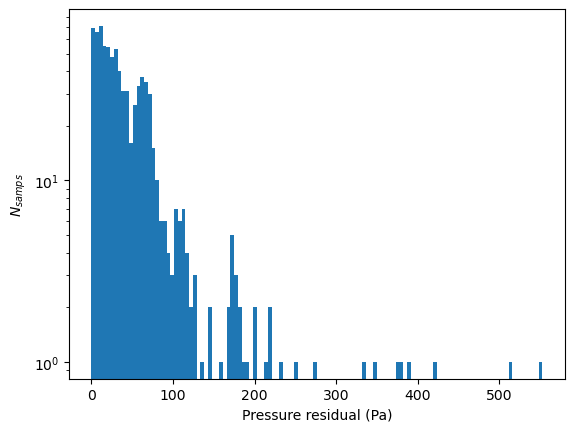

In [125]:
# Focus on high altitude, low pressure side, cut high residuals
plt.hist(np.abs(pressure_residual[alt_vec_interp > 15.e3]), bins=120)
plt.yscale('log')
plt.xlabel('Pressure residual (Pa)')
plt.ylabel(r'$N_{samps}$')

plt.show()
plt.close()

In [126]:
# Put cut on high-altitude, large residual samples
bad_pressure_mask = (alt_vec_interp > 15.e3) * (np.abs(pressure_residual) > 200.)
print(np.sum(bad_pressure_mask))

16


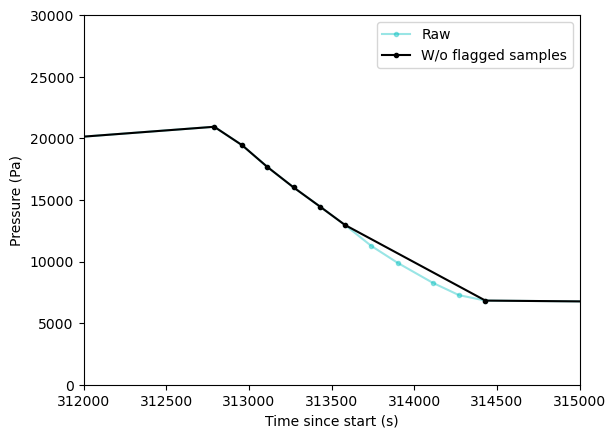

In [128]:
#Examine a cut area
plt.plot(pressure_ctime - pressure_ctime[0], pressure_vec, 'c.-', alpha=0.4, label='Raw')
plt.plot(pressure_ctime[~bad_pressure_mask] - pressure_ctime[0], pressure_vec[~bad_pressure_mask], 'k.-', label='W/o flagged samples')
plt.legend()
plt.xlabel('Time since start (s)')
plt.ylabel('Pressure (Pa)')
plt.xlim(312000, 315000)
plt.ylim(0, 30000)

plt.show()
plt.close()
# Deviation from model not extreme -- maybe tens of %

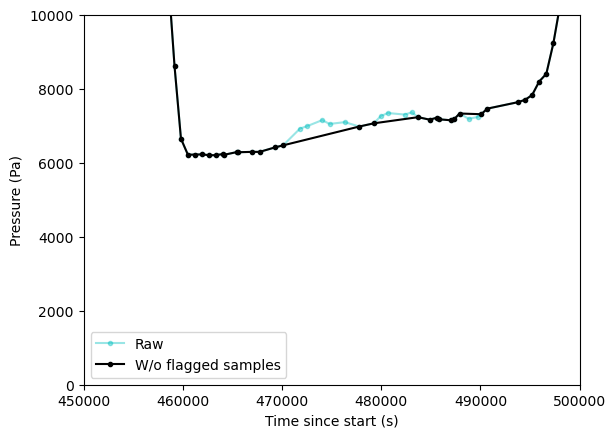

In [129]:
# Another region
plt.plot(pressure_ctime - pressure_ctime[0], pressure_vec, 'c.-', alpha=0.4, label='Raw')
plt.plot(pressure_ctime[~bad_pressure_mask] - pressure_ctime[0], pressure_vec[~bad_pressure_mask], 'k.-', label='W/o flagged samples')
plt.legend()
plt.xlabel('Time since start (s)')
plt.ylabel('Pressure (Pa)')
plt.xlim(450000, 500000)
plt.ylim(0, 10000)

plt.show()
plt.close()

In [166]:
# Save output
field_order = np.argsort([np.amin(np.where(sensor_field == field)[0]) for field in fields])
sorted_field_order = fields[field_order]
print(sorted_field_order)

fields_to_loop = ['humidity']
fields_to_loop.extend(sorted_field_order[2:])
times_to_loop = [ct, ct, ct, pressure_ctime]
vecs_to_loop = [h_vec, temp_vec, alt_vec, pressure_vec]
cuts_to_loop = [~bad_h_mask, ~bad_temp_mask, ~bad_alt_mask_v2, ~bad_pressure_mask]

full_output = []

for i, field in enumerate(fields_to_loop):
    print(field)
    # Control presentation of vecs to strings
    times = np.char.mod('%.1f', times_to_loop[i])
    vec = np.char.mod('%.2f', vecs_to_loop[i])
    print(cuts_to_loop[i].size - np.sum(cuts_to_loop[i]))
    cut = np.char.mod('%i', cuts_to_loop[i])
    
    field_arr = np.vstack((np.array([field for i in range(times_to_loop[i].size)]), times, vec, cut)).T
    print(field_arr.shape, field_arr.dtype, field_arr[0])
    full_output.append(field_arr)

['humidity_1' 'humidity_2' 'temperature_ambient' 'gps_altitude' 'pressure']
humidity
14568
(66982, 4) <U12 ['humidity' '1784012830.0' '52.12' '1']
temperature_ambient
138
(66982, 4) <U19 ['temperature_ambient' '1784012830.0' '32.19' '1']
gps_altitude
404
(66982, 4) <U12 ['gps_altitude' '1784012830.0' '211.48' '1']
pressure
16
(1397, 4) <U12 ['pressure' '1784012875.0' '96735.70' '1']


In [162]:
full_output_arr = np.vstack(tuple(full_output))
print(full_output_arr.shape)

(202343, 4)


In [163]:
print(sensor_ctime.size - ct.size, sensor_val.size - ct.size) # Making sure size consistent after combining H1+H2

202343 202343


In [164]:
np.savetxt('W-9279-with-cuts.csv', full_output_arr, fmt='%s', delimiter=',', 
           header='field,timestamp,value,samp_ok')